### Trajectory Analysis and Integration of Modalities using Kidney IgAN (Pathomics) Data with PILOT

<div class="alert alert-block alert-info">
<b>PILOT</b>

Welcome to the PILOT Package Tutorial for pathomics Data!
With this tutorial, we learn not only how to analyze the Pathomics Data but also how to integrate multimodal data with PILOT. 
 
You can find the pathomics data [here](https://github.com/CostaLab/PILOT/tree/main/Tutorial/Datasets).

</div>

In [ ]:
import pilotpy as pl
import scanpy as sc

#### Kidney_IgAN Tubuli (first modality)

##### Reading Anndata
<div class="alert alert-block alert-info">
The Anndata (h5ad) file is in the Datasets folder.
</div>

In [ ]:
adata_T=sc.read_h5ad('Datasets/Kidney_IgAN_T.h5ad') 

#### Loading the required information and computing the Wasserstein distance:
<div class="alert alert-block alert-info"> In order to work with PILOT, ensure that your Anndata object is loaded and contains the required information.
    
Use the following parameters to configure PILOT for your analysis (Setting Parameters):
    
- adata: Pass your loaded Anndata object to PILOT.
    
- emb_matrix: Provide the name of the variable in the obsm level that holds the dimension reduction ( PCA representation).
    
- clusters_col: Specify the name of the column in the observation level of your Anndata that corresponds to cell types or clusters.
    
- sample_col: Indicate the column name in the observation level of your Anndata that contains information about samples or patients.
    
- status: Provide the column name that represents the status or disease (e.g., "control" or "case").
  
</div>

In [ ]:
pl.tl.wasserstein_distance(
    adata_T,
    clusters_col = 'Cell_type',
    sample_col = 'sampleID',
    status = 'status', 
    data_type = 'Pathomics'
    )

##### Cost matrix:
<div class="alert alert-block alert-info">
The cost matrix shows how different the cell types are from each other (the distance between the cell types). PILOT uses it as the cost of moving cells from one cell type to another when it compares two samples. Dark blue means similar cell types.

At this point, you should have a 'Results_PILOT' folder inside the folder where you are running your analysis, which includes all the plots created by PILOT.
</div>

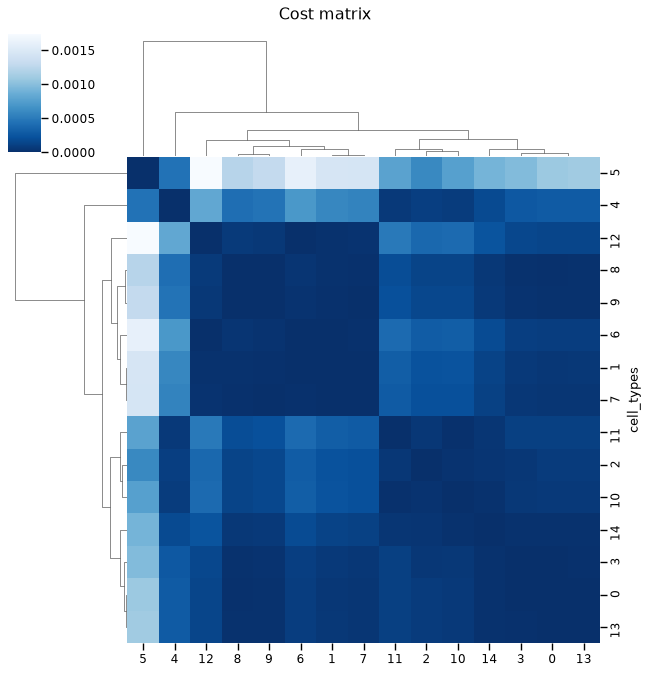

In [ ]:
pl.pl.heatmap_cost(adata_T)

##### Wasserstein distance:
<div class="alert alert-block alert-info">
The Wasserstein distance shows how different the samples (patients) are. It compares the cell type proportions of two samples, using the cost matrix above. Dark blue means similar samples. The rows and columns are clustered, so similar samples are placed next to each other.
</div>

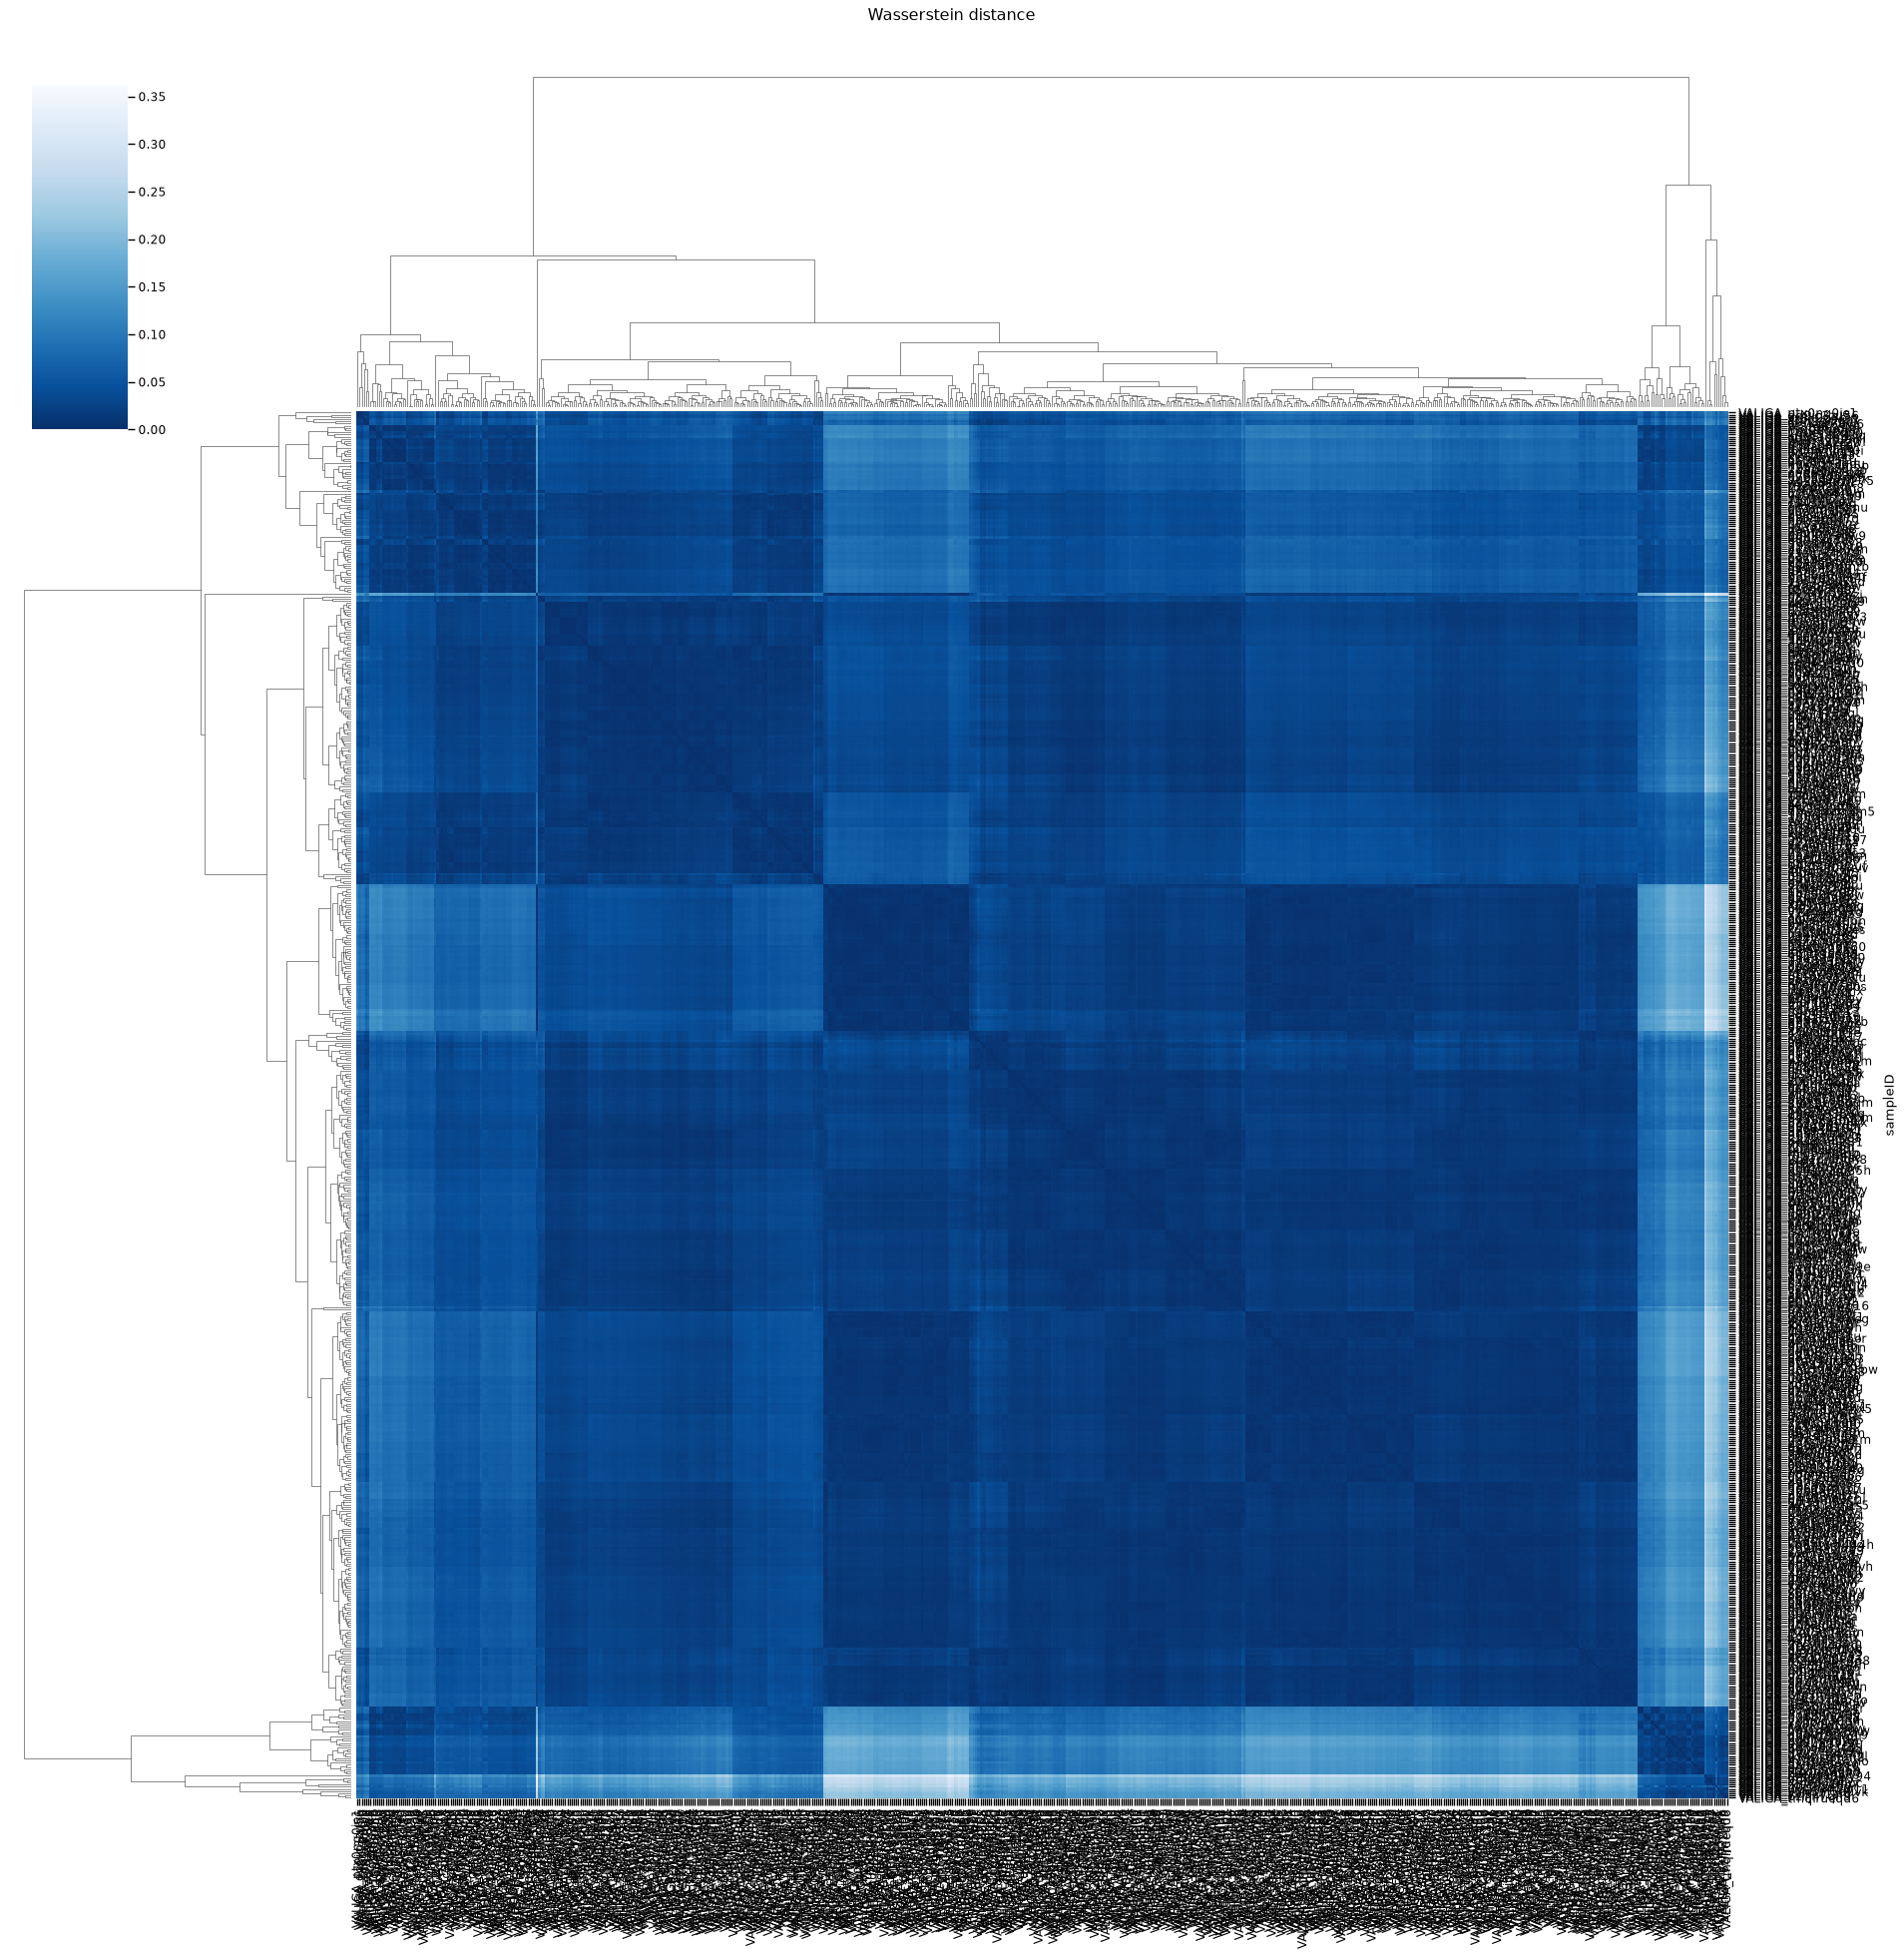

In [ ]:
pl.pl.heatmap_wasserstein(adata_T)

##### Trajectory:
<div class="alert alert-block alert-info">
Here we show the diffusion map of the Wasserstein distances (the trajectory). In the upcoming trajectory analysis, the labels "<30" mean an eGFR level below 30 (considered as Low), "30-60" denotes a reduced eGFR range (marked as Reduced), and ">60" indicates a normal eGFR level.

Each point is a sample, colored by its status. The parameters that change the trajectory are:

- `epsilon` (default 1): width of the kernel. Small values link each sample only to its most similar samples; large values give a smoother trajectory. `epsilon = 'bgh'` chooses it automatically.
- `alpha` (default 0.5, between 0 and 1): with 1, groups with many samples do not dominate the trajectory.
- `n_neighbors` (default 64): number of neighbor samples used for each sample. It only has an effect when it is smaller than the number of samples.
- `n_evecs` (default 2): number of diffusion components.

The other parameters only change the look of the plot (colors, legend, point size, ...). Run `pl.pl.trajectory?` or press Shift+Tab in Jupyter to see all parameters.
</div>

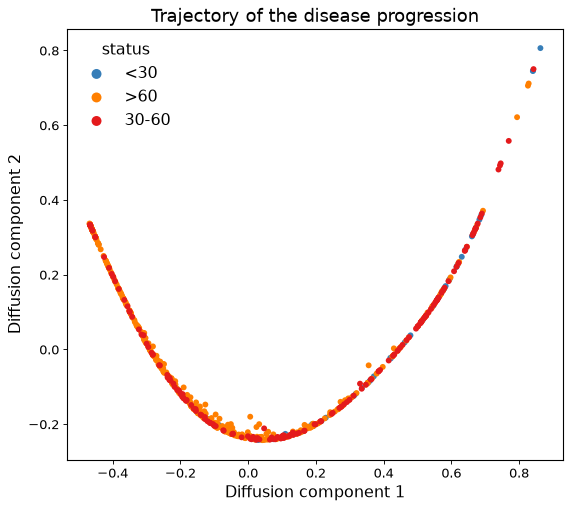

In [ ]:
pl.pl.trajectory(adata_T)

##### UMAP of the samples:
<div class="alert alert-block alert-info">
PILOT can also show the samples in a UMAP computed from the Wasserstein distances. Important parameters:

- `n_neighbors` (default 15, or fewer for small cohorts): small values keep the local structure, large values the global structure.
- `min_dist` (default 0.5): how close the points can be to each other.
</div>

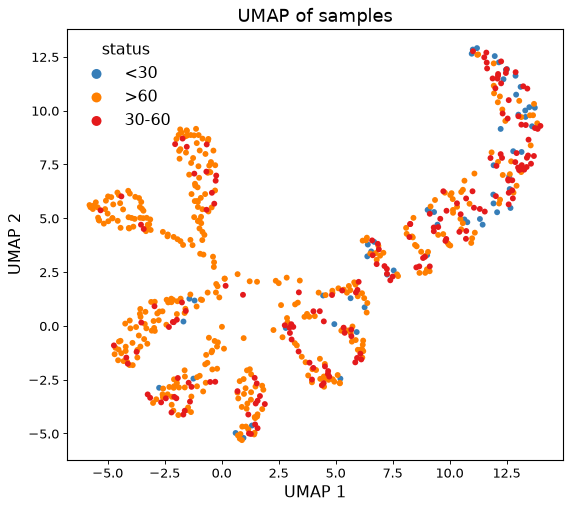

In [ ]:
pl.pl.umap_samples(adata_T)

#### Kidney_IgAN Glomeruli (second modality)

##### Reading Anndata
<div class="alert alert-block alert-info">
The Anndata (h5ad) file is in the Datasets folder.
   </div>

In [ ]:
adata_G=sc.read_h5ad('Datasets/Kidney_IgAN_G.h5ad') #First read the object

In [ ]:
pl.tl.wasserstein_distance(
    adata_G,
    clusters_col = 'Cell_type',
    sample_col = 'sampleID',
    status = 'status',
    data_type = 'Pathomics'
    )

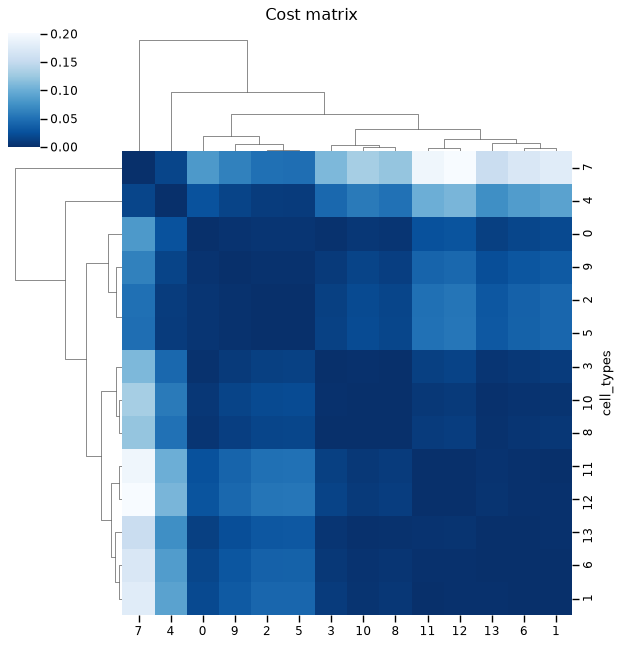

In [ ]:
pl.pl.heatmap_cost(adata_G)

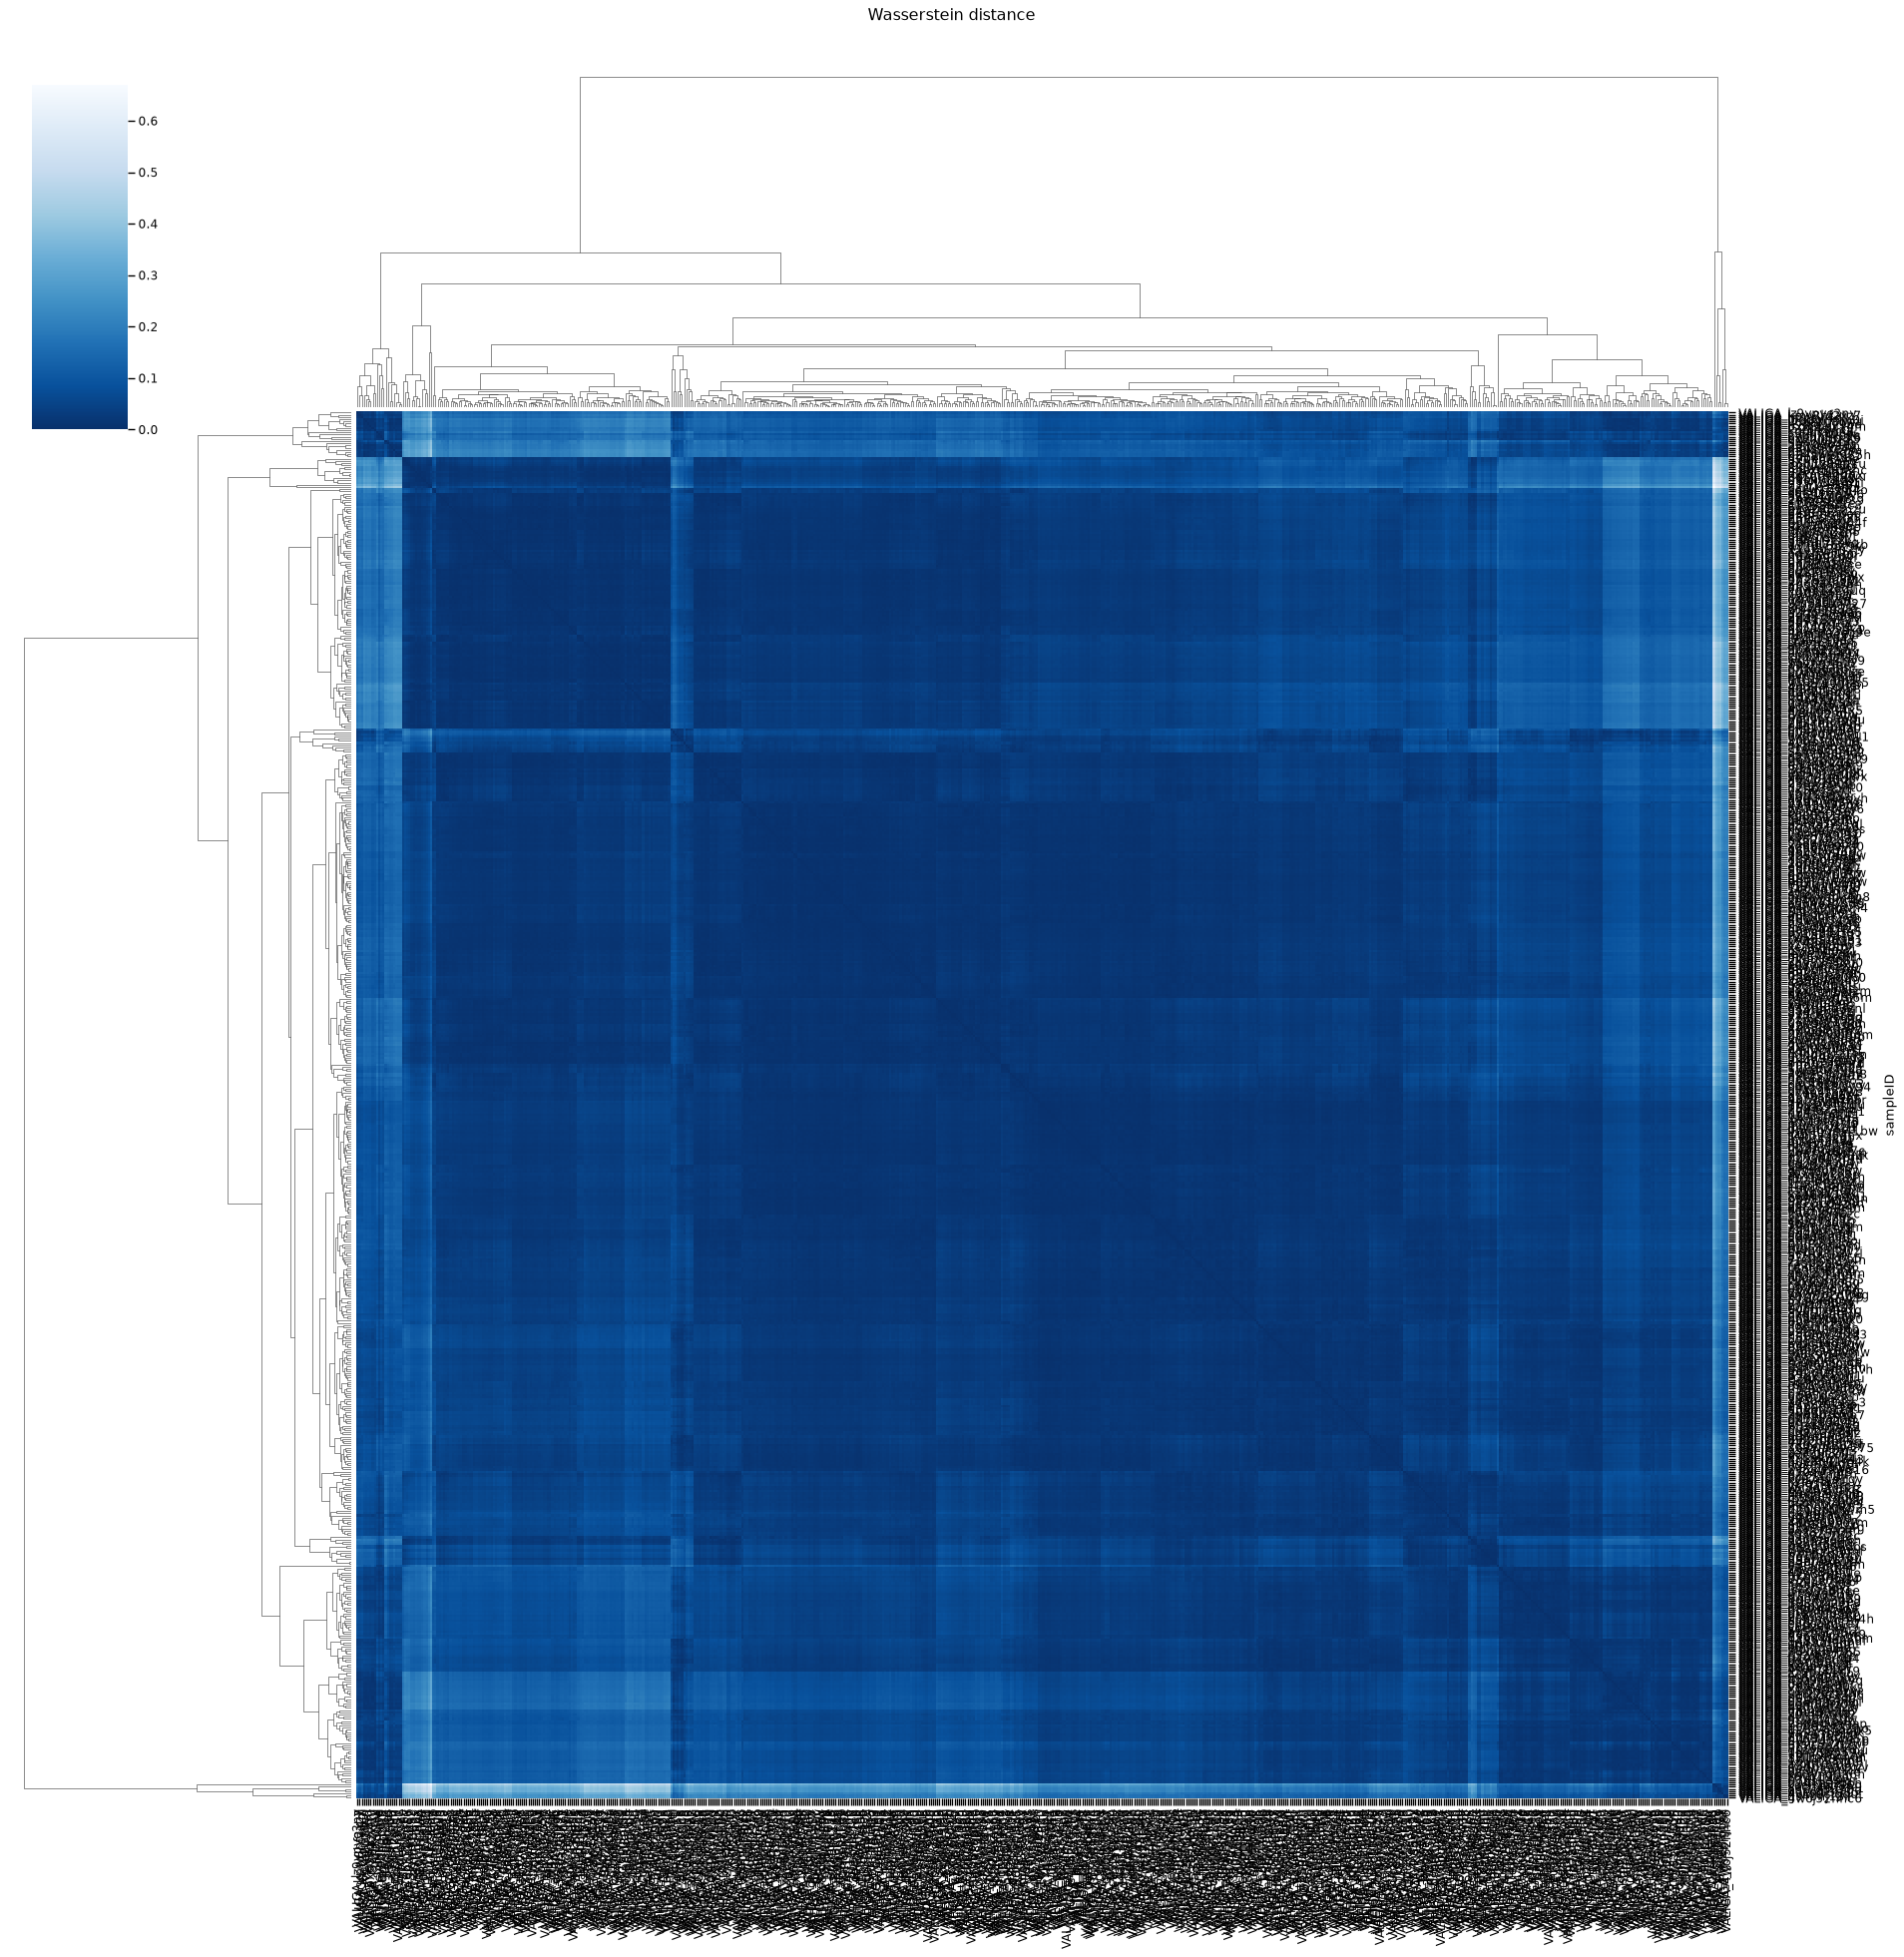

In [ ]:
pl.pl.heatmap_wasserstein(adata_G)

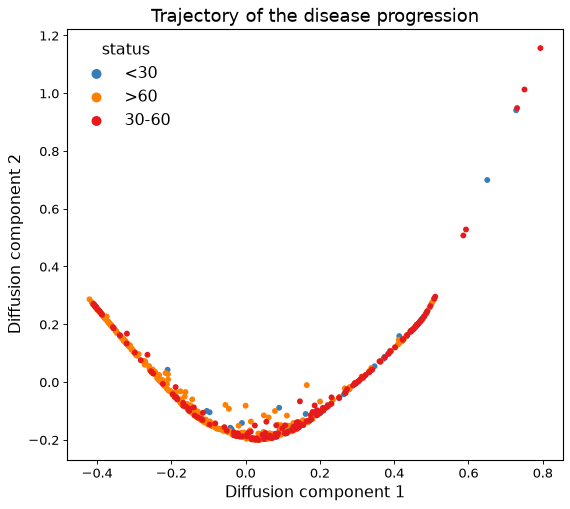

In [ ]:
pl.pl.trajectory(adata_G)

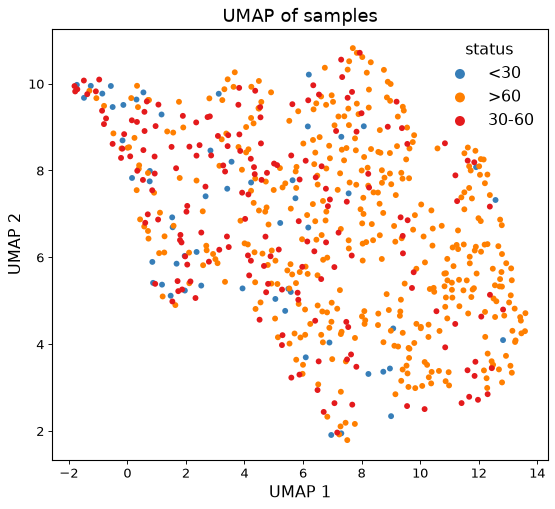

In [ ]:
pl.pl.umap_samples(adata_G)

####  Integration of modalities:
<div class="alert alert-block alert-info"> 
Here, we integrate the distances from the first (Tubuli) and second (Glomeruli) modalities. We get the sum of the distances of samples.
</div>

In [ ]:
adata_Com = adata_G
adata_Com.uns['EMD'] = adata_G.uns['EMD'] + adata_T.uns['EMD']

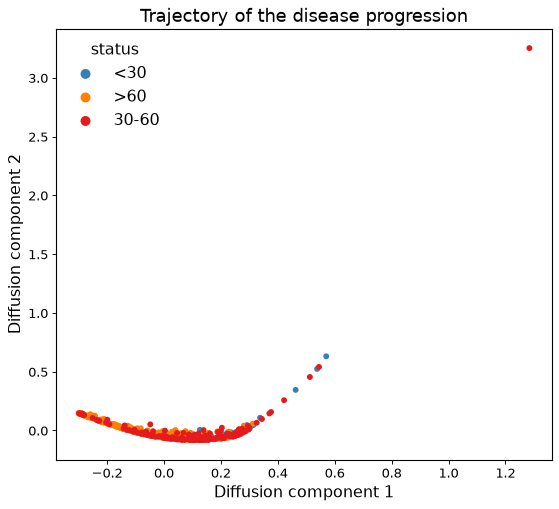

In [ ]:
pl.pl.trajectory(adata_Com)

##### UMAP of the samples:
<div class="alert alert-block alert-info">
PILOT can also show the samples in a UMAP computed from the Wasserstein distances. Important parameters:

- `n_neighbors` (default 15, or fewer for small cohorts): small values keep the local structure, large values the global structure.
- `min_dist` (default 0.5): how close the points can be to each other.
</div>

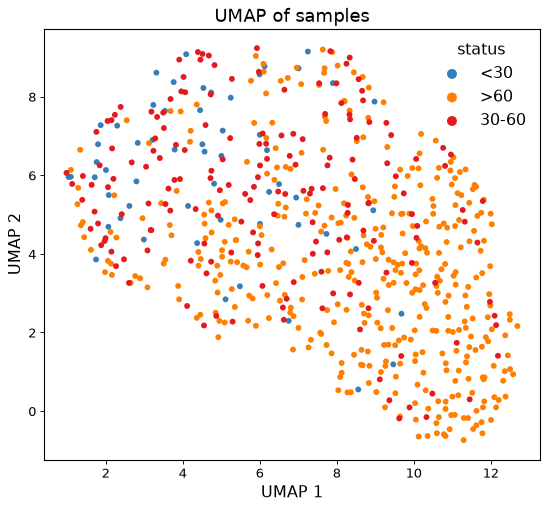

In [ ]:
pl.pl.umap_samples(adata_Com)

####  Fit a principal graph:
<div class="alert alert-block alert-info">
The diffusion map creates an embedding that potentially reveals a trajectory in the data. Next, PILOT uses ElPiGraph to fit a principal graph (a tree) through the samples and orders the samples along it, starting from the root. This order is the disease progression score (pseudotime). Here, the trajectory starts at the samples with a normal eGFR (">60"). Important parameters:

- `source_node`: the start (root) of the trajectory. With `'auto'`, PILOT chooses the end node of the graph where the samples of `root_status` come first. You can also give a node number (the numbers are shown in the plot).
- `root_status`: the group where the trajectory starts, here `'>60'`.
- `NumNodes` (default 20): number of nodes of the graph. More nodes give a more detailed curve.
</div>

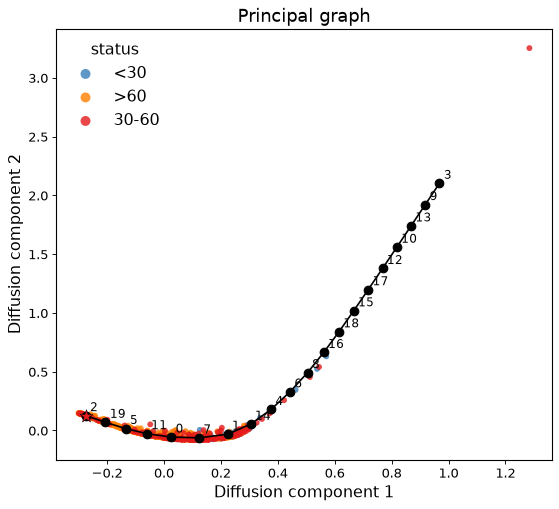

In [ ]:
pl.pl.fit_pricipla_graph(adata_Com, source_node = 'auto', root_status = '>60')

##### Clinical and technical variables on the trajectory:
<div class="alert alert-block alert-info">
The trajectory and the principal graph are computed from the status. To see how other information about the samples relates to the disease progression, PILOT can color the samples by any column of `adata.obs`, e.g. the age or the sex of the patients. The trajectory and the principal graph (grey, with the root as a red star) stay the same.

- Categorical variables (e.g. sex, batch) get one color per group.
- Numeric variables (e.g. age, or a technical value such as the percentage of mitochondrial reads) get a color scale. Values that are given per cell are averaged per sample (`agg = 'mean'`).
- `variable = 'pseudotime'` and `variable = 'n_cells'` (number of cells of each sample) can also be used.
</div>

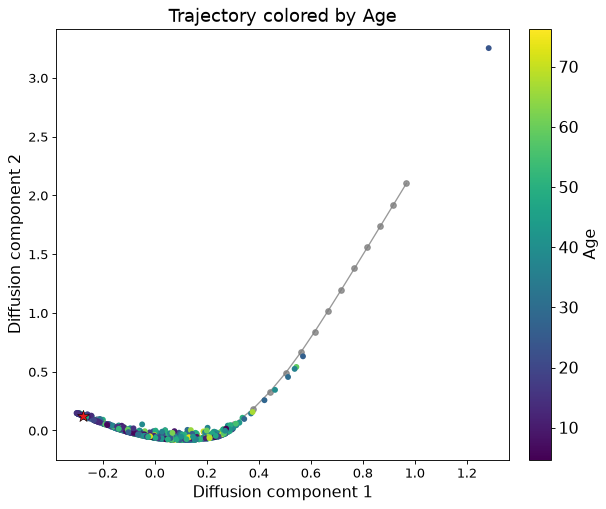

In [ ]:
pl.pl.trajectory_variable(adata_Com, variable = 'Age')

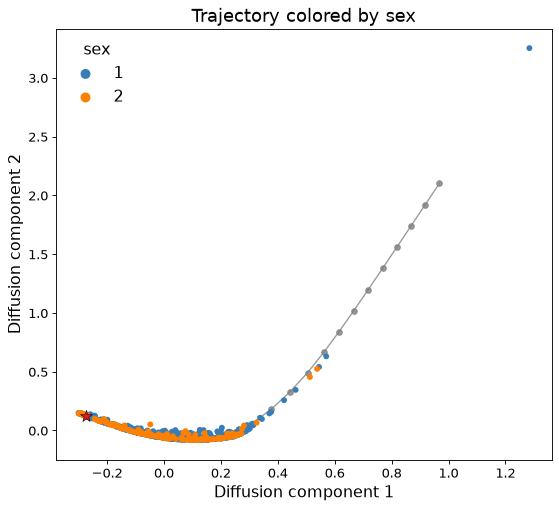

In [ ]:
pl.pl.trajectory_variable(adata_Com, variable = 'sex')

The same variables can be shown on the UMAP of the samples:

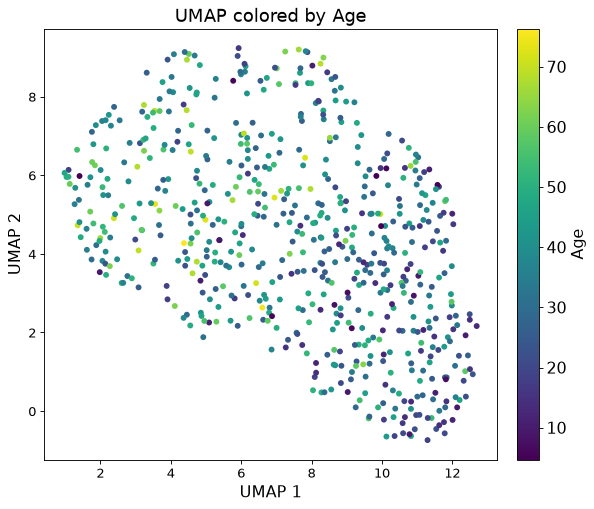

In [ ]:
pl.pl.umap_variable(adata_Com, variable = 'Age')

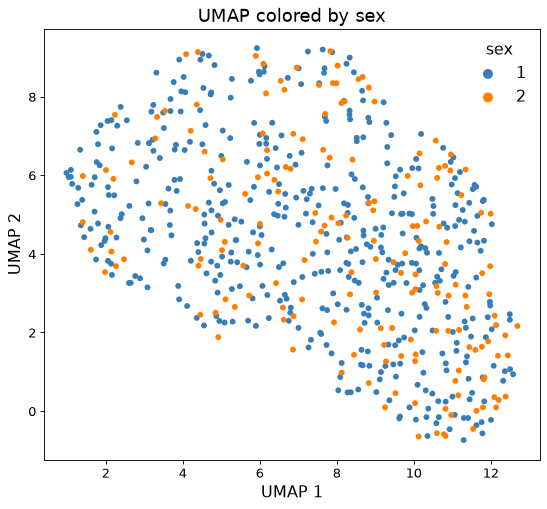

In [ ]:
pl.pl.umap_variable(adata_Com, variable = 'sex')

##### Cell-type Importance Glomeruli:
<div class="alert alert-block alert-info">
Next, we use a regression model to find cell types whose proportions change linearly or non-linearly with disease progression. 

`pl.tl.cell_importance_calculation` orders the samples along the trajectory and, for each cell type, fits a linear, a quadratic and a linear + quadratic model of its proportion, and keeps the best one. Important parameters:

- `p_val` (default 1): keep only the cell types with an adjusted p-value below this value; 1 keeps all of them.
- `x_axis`: `'order'` (default) places the samples at their position along the trajectory (1, 2, 3, ...); `'pseudotime'` uses the pseudotime values, so the distances between the samples are kept.

The results are saved in 'Results_PILOT/Cell_type_Report' and the cell types in `adata.uns['cellnames']`.
</div>

In [ ]:
pl.tl.cell_importance_calculation(adata_Com)

The heatmap shows the cell type proportions (columns) of each sample (rows). The samples are ordered along the trajectory, from the start (top) to the end (bottom). Each cell type is scaled between 0 and 1, so its changes are easy to see.

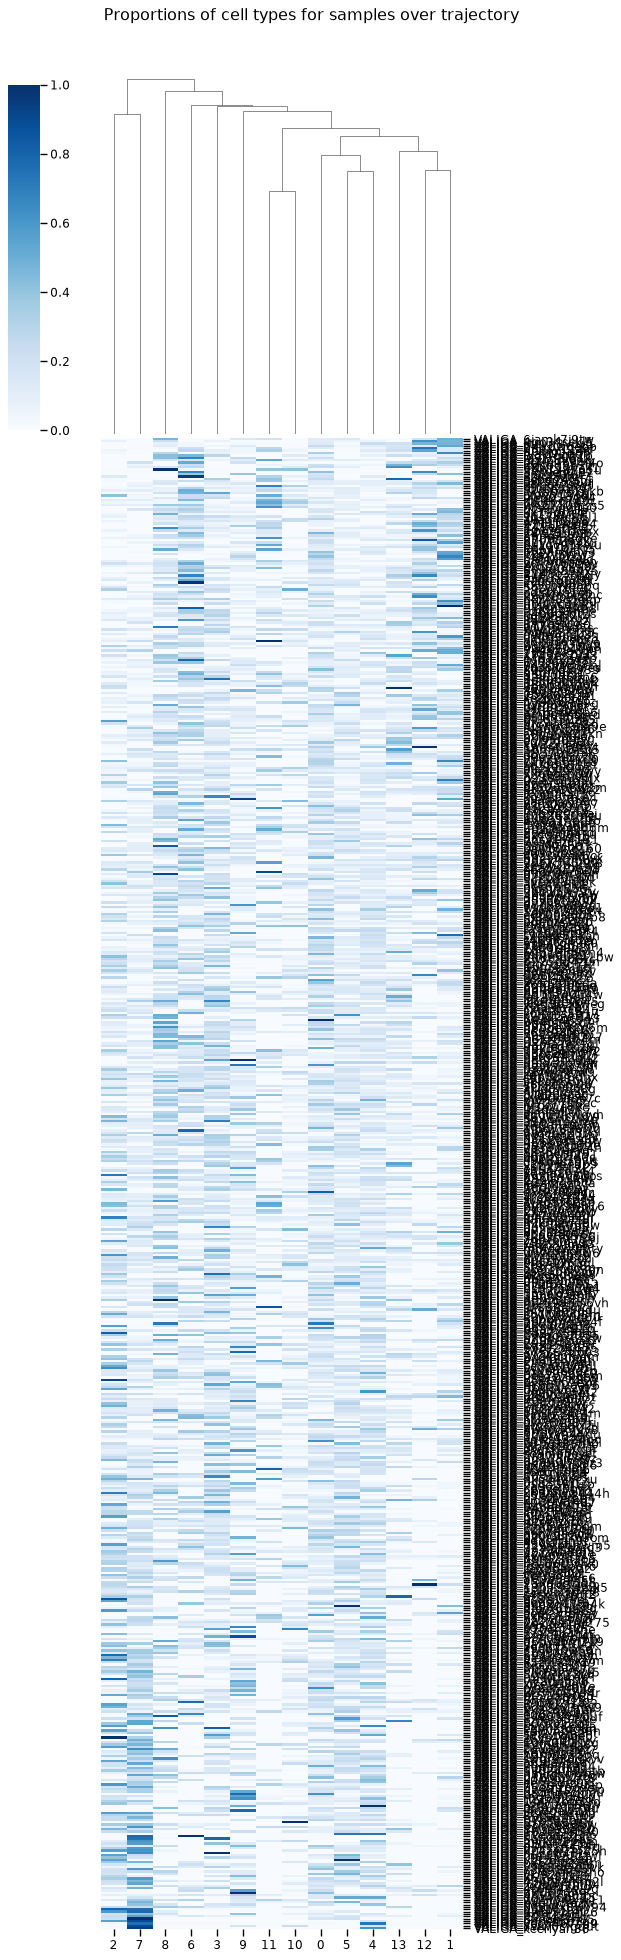

In [ ]:
pl.pl.heatmap_proportions(adata_Com)

Each panel shows one cell type: its proportion in each sample (points) along the trajectory and the fitted curve. The panels are sorted by p-value; cell types with an adjusted p-value below 0.05 have a bold title. `pl.pl.cell_importance_plot(adata)` saves the same plots as one file per cell type (in 'Results_PILOT/Cell_types_importance'), and `pl.tl.cell_importance(adata)` runs these three steps in one call.

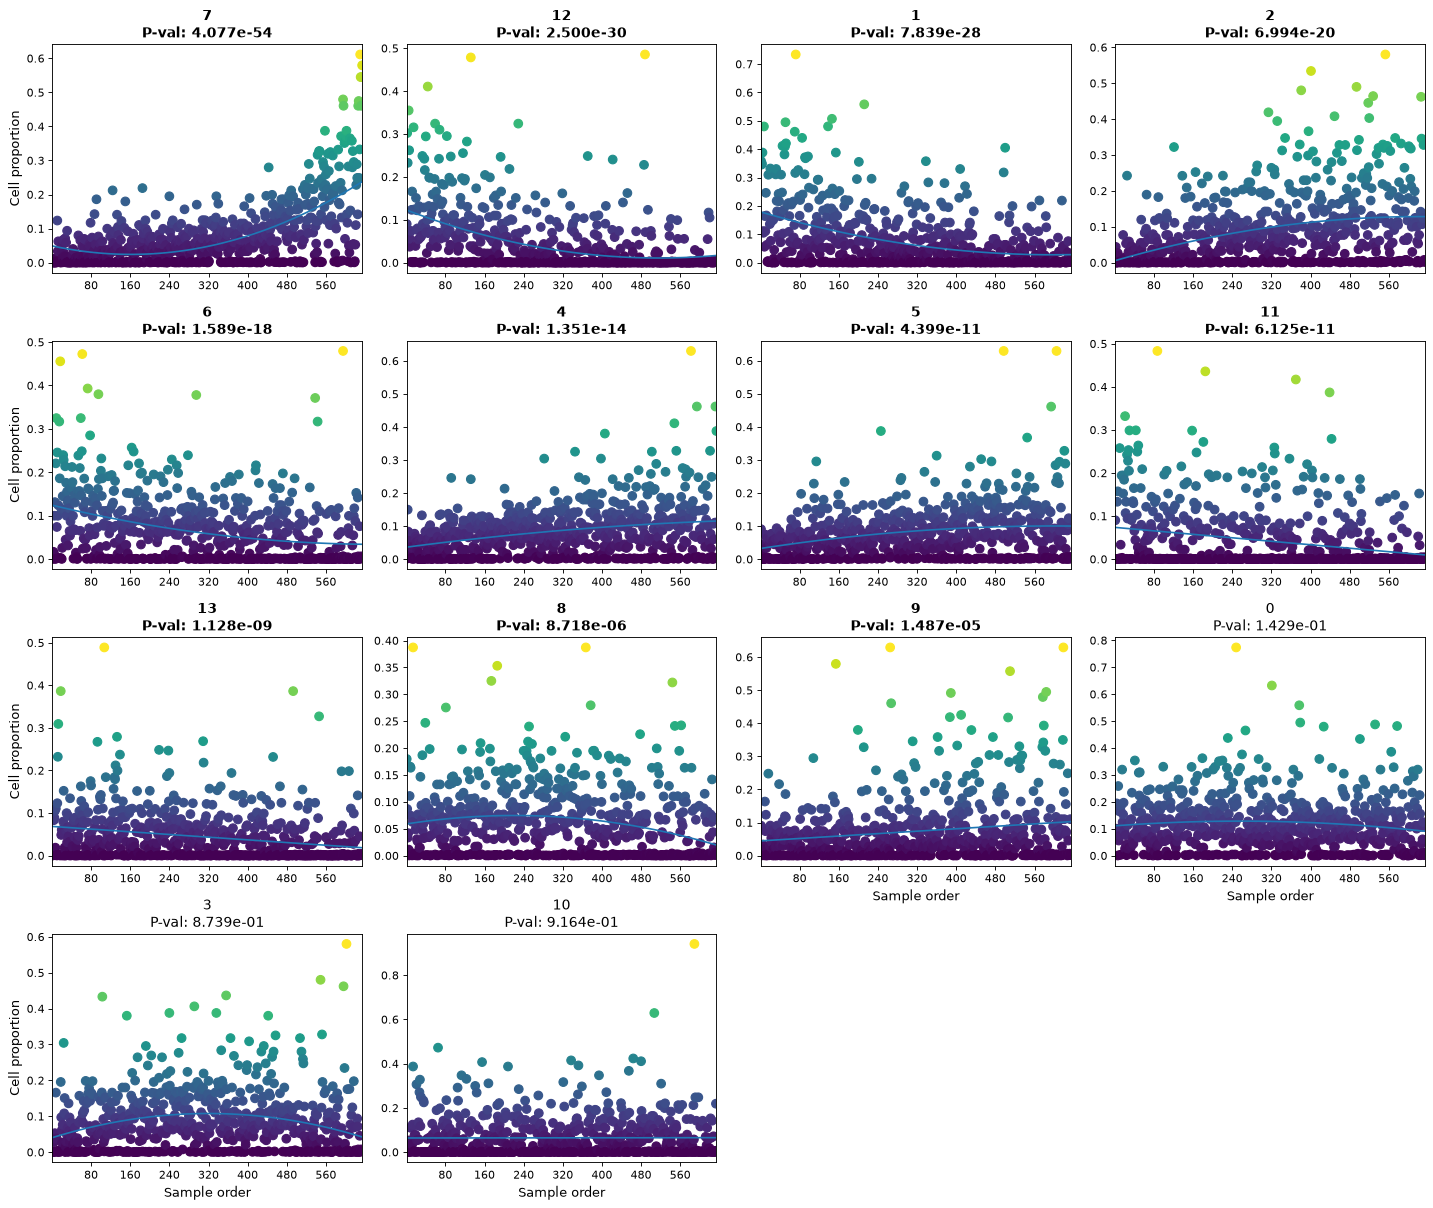

In [ ]:
pl.pl.cell_importance_grid(adata_Com)

#### Feature selection for Glomeruli based on Combination:

##### Saving morphological features and maps them with the obtained order by PILOT  (for Glomeruli):

<div class="alert alert-block alert-info">     
In this step, morphological features are extracted from all clusters and linked to pseudotime using the PILOT trajectory order.

- The "extract_cells_from_pathomics" function creates a 'cells' folder inside the 'Results_PILOT' folder to store these morphological features and corresponding pseudotime values as 'All.csv'.
</div>

In [14]:
pl.tl.extract_cells_from_pathomics(adata_Com)

##### Getting the log scale of features 

In [15]:
data=pl.tl.norm_morphological_features(
 column_names = ['glom_sizes', 'glom_distance_to_closest_glom','glom_diameters','glom_tuft_sizes',
                 'glom_bowman_sizes'],
 name_cell = 'All'
    )

##### Morphological features changes for Glomeruli:

<div class="alert alert-block alert-info">
      
 Firstly, we should note that for pathomics data, instead of using cluster-specific changes for features/genes (please see MI tutorial analysis), we use the fit models to find the structural changes. 
    
We apply the morphological_features_importance function to catch the features/structures that are changing over the trajectory (combination) for Glomeruli.
</div>

Name of Cluster : All
Sparsity:6.486269746268921e-05
For this cell_type, p-value of  14 genes are statistically significant.
  Expression pattern  count
0        linear down      6
1          linear up      4
2     quadratic down      2
3       quadratic up      2
data saved successfully


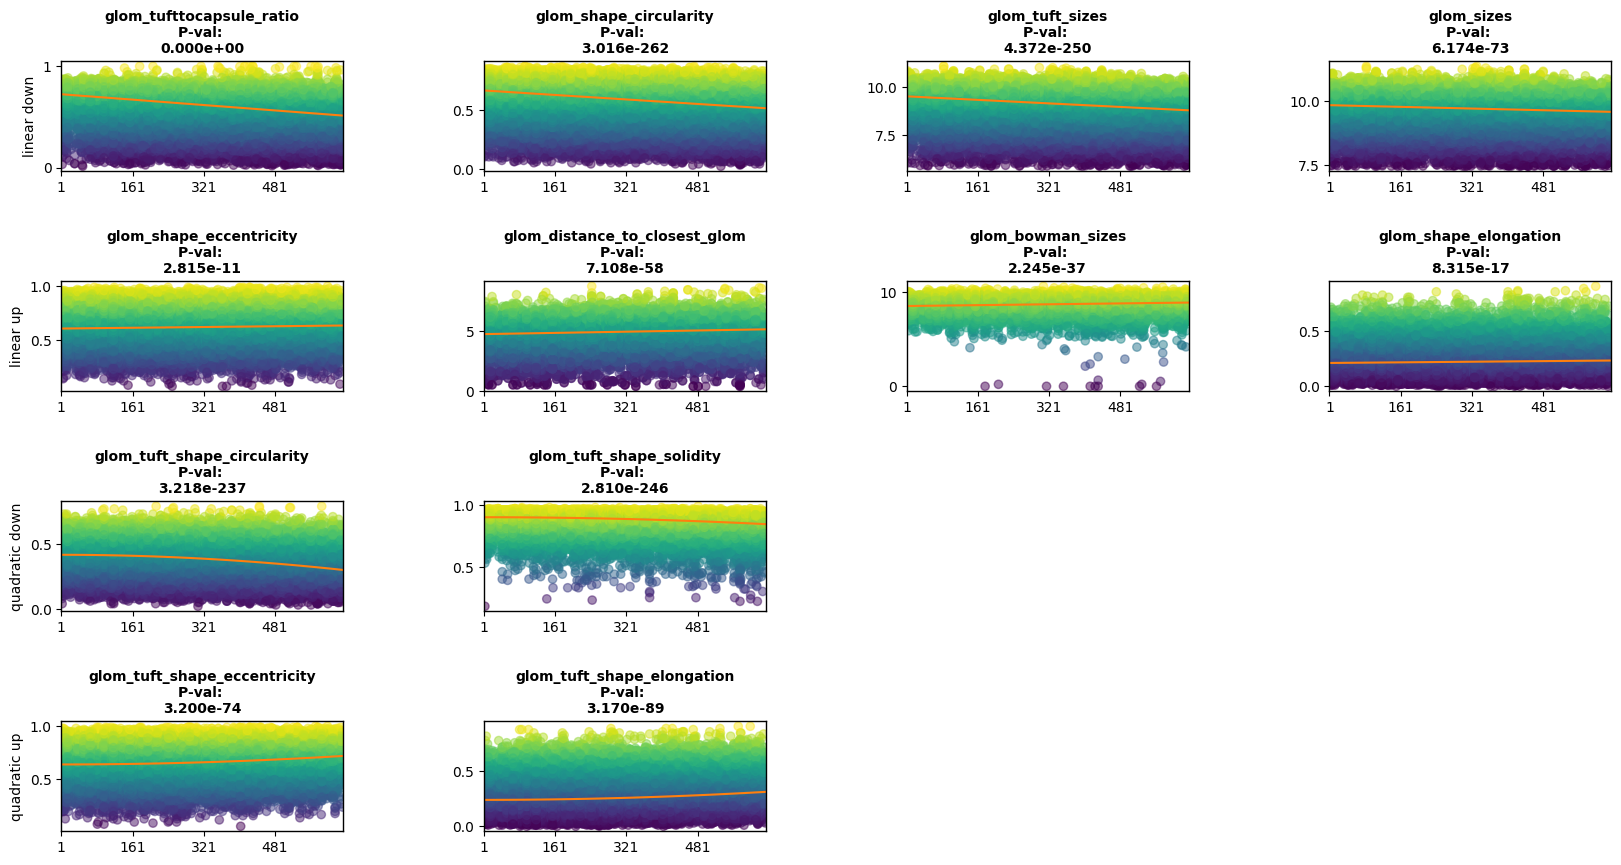

In [16]:
pl.tl.morphological_features_importance(data, height = 10, x_lim = 160, width = 20)    

#### Feature selection for Tubuli based on Combination
<div class="alert alert-block alert-info">

We repeat the same process for Tubuli.
</div>

#### Saving morphological features and map them with the obtained order by PILOT  (for Tubuli):


In [17]:
adata_T.uns['orders'] = adata_Com.uns['orders']
pl.tl.extract_cells_from_pathomics(adata_T)

#####  Getting the log scale of features 

In [18]:
data=pl.tl.norm_morphological_features(
 column_names = ['tubule_diameters', 'tubule_sizes', 'tubule_distance_to_closest_instance'],
 name_cell = 'All'
    )

##### Morphological features changes for Tubuli

Name of Cluster : All
Sparsity:0.0
For this cell_type, p-value of  3 genes are statistically significant.
  Expression pattern  count
0        linear down      2
1          linear up      1
data saved successfully


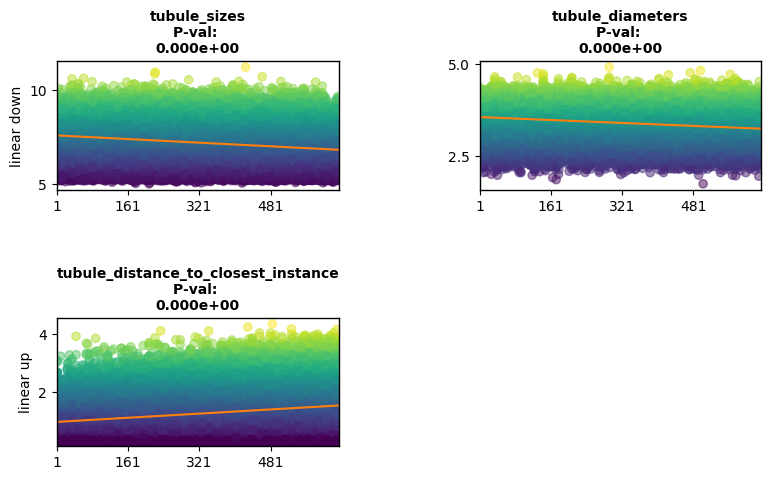

In [19]:
pl.tl.morphological_features_importance(data, x_lim = 160, height = 5)    